## Interpolation and curve fitting

`interp1` fills in values between samples. `'linear'` joins them with straight lines; `'spline'` passes a smooth cubic through them, which can overshoot; `'pchip'` keeps each piece monotone between its samples, so it never overshoots a step.

spline range [-0.042, 1.092], pchip range [0.000, 1.000]


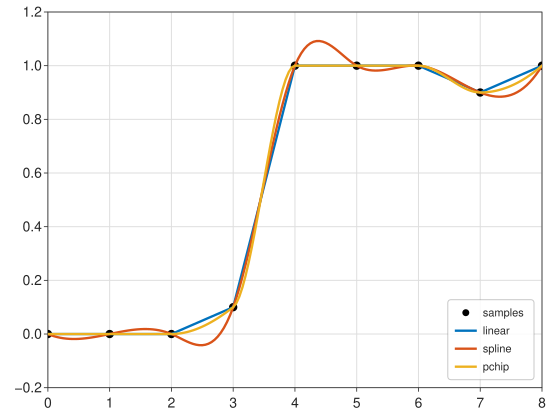

In [ ]:
x = 0:8;
y = [0 0 0 0.1 1 1 1 0.9 1];
xq = linspace(0, 8, 161);
figure
plot(x, y, 'ko', xq, interp1(x, y, xq), xq, interp1(x, y, xq, 'spline'), xq, interp1(x, y, xq, 'pchip'), 'LineWidth', 1.2)
legend('samples', 'linear', 'spline', 'pchip', 'Location', 'southeast'), grid on
fprintf('spline range [%.3f, %.3f], pchip range [%.3f, %.3f]\n', min(interp1(x, y, xq, 'spline')), max(interp1(x, y, xq, 'spline')), ...
    min(interp1(x, y, xq, 'pchip')), max(interp1(x, y, xq, 'pchip')))

### One polynomial through many points: Runge's example

The polynomial of degree 10 through 11 equally spaced samples of $f(x) = 1/(1 + 25x^2)$ swings wildly near the ends, while a cubic spline through the same samples stays close. `polyfit` with as many coefficients as points interpolates.

largest error: polynomial 1.916, spline 0.022


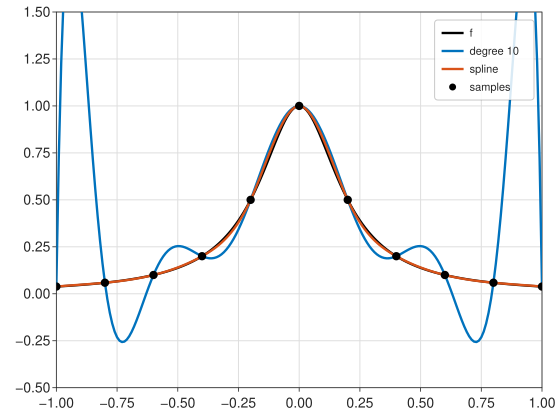

In [ ]:
f = @(x) 1 ./ (1 + 25*x.^2);
xs = linspace(-1, 1, 11);
t = linspace(-1, 1, 201);
p = polyfit(xs, f(xs), 10);
figure
plot(t, f(t), 'k', t, polyval(p, t), t, spline(xs, f(xs), t), xs, f(xs), 'ko', 'LineWidth', 1.2)
legend('f', 'degree 10', 'spline', 'samples'), ylim([-0.5 1.5]), grid on
fprintf('largest error: polynomial %.3f, spline %.3f\n', max(abs(polyval(p, t) - f(t))), max(abs(spline(xs, f(xs), t) - f(t))))

Samples at the Chebyshev points $x_k = \cos(k\pi/n)$, crowded toward the ends, tame the polynomial.

In [ ]:
xc = cos(pi*(0:10)/10);
pc = polyfit(xc, f(xc), 10);
fprintf('Chebyshev points: largest error %.3f\n', max(abs(polyval(pc, t) - f(t))))

Chebyshev points: largest error 0.132


### Least squares

With more points than coefficients, `polyfit` minimizes $\sum_i (p(x_i) - y_i)^2$. Its second output carries the residual norm, and a third output centers and scales $x$, which keeps high degrees well conditioned. The same fit is `A \ y` with the columns of `A` the powers of $x$.

degree 1: residual norm 5.2803
degree 2: residual norm 1.0646
degree 3: residual norm 0.7960
degree 4: residual norm 0.6754
degree 5: residual norm 0.6671
same cubic from backslash: 1


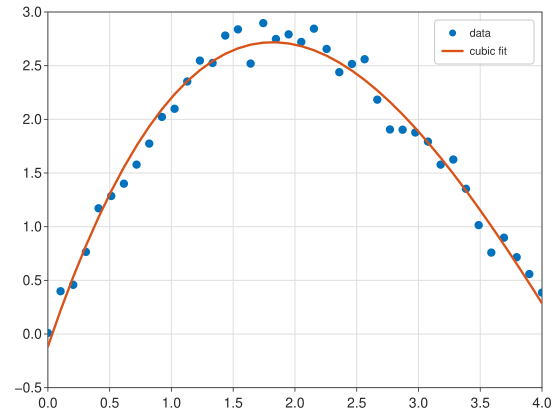

In [ ]:
rng(3)
xd = linspace(0, 4, 40)';
yd = 2*sin(xd) + 0.5*xd + 0.15*randn(size(xd));
for d = 1:5
    [~, S] = polyfit(xd, yd, d);
    fprintf('degree %d: residual norm %.4f\n', d, S.normr)
end
[p3, S, mu] = polyfit(xd, yd, 3);
A = [xd.^3 xd.^2 xd ones(size(xd))];
c = A \ yd;
fprintf('same cubic from backslash: %d\n', norm(polyfit(xd, yd, 3)' - c) < 1e-10)
figure
plot(xd, yd, 'o', xd, polyval(p3, xd, [], mu), 'LineWidth', 1.2), legend('data', 'cubic fit'), grid on

### A nonlinear model

A decay $y = a e^{-bt}$ is not linear in $b$. `fminsearch` minimizes the sum of squared residuals directly; taking logarithms instead turns it into a straight-line fit, a good starting point.

from the logs: a = 3.1031, b = 0.7107


least squares: a = 3.0170, b = 0.6798


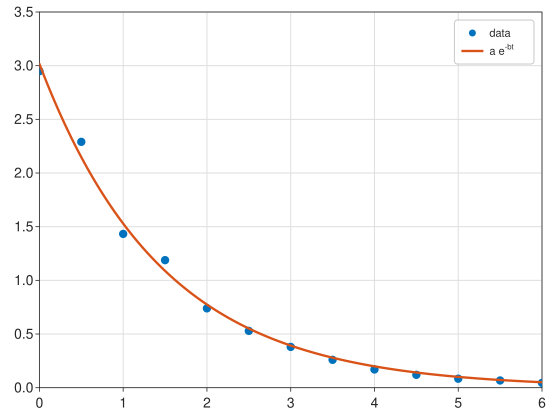

In [ ]:
rng(5)
td = (0:0.5:6)';
yd = 3*exp(-0.7*td) .* (1 + 0.05*randn(size(td)));
start = polyfit(td, log(yd), 1);
c0 = [exp(start(2)), -start(1)];
model = @(c, t) c(1)*exp(-c(2)*t);
c = fminsearch(@(c) sum((model(c, td) - yd).^2), c0);
fprintf('from the logs: a = %.4f, b = %.4f\n', c0)
fprintf('least squares: a = %.4f, b = %.4f\n', c)
figure
tt = linspace(0, 6, 200);
plot(td, yd, 'o', tt, model(c, tt), 'LineWidth', 1.2), legend('data', 'a e^{-bt}'), grid on

### Smoothing

`movmean` averages over a sliding window: a cheap way to see the trend under noise before fitting anything.

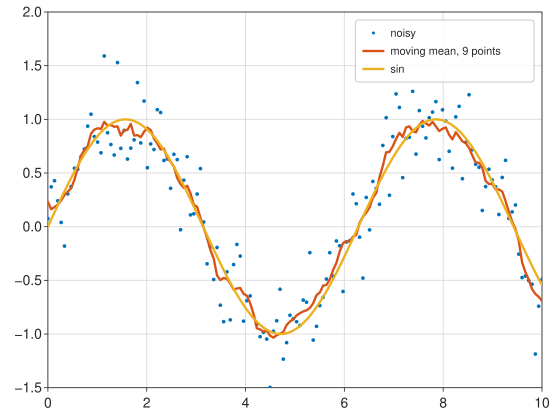

In [ ]:
rng(8)
s = linspace(0, 10, 150);
noisy = sin(s) + 0.3*randn(size(s));
figure
plot(s, noisy, '.', s, movmean(noisy, 9), s, sin(s), 'LineWidth', 1.2)
legend('noisy', 'moving mean, 9 points', 'sin'), grid on

### Two dimensions

`interp2` refines a coarse grid, here a 6-by-6 sampling of $z = \sin x \cos y$, bilinearly or with cubics. The contours of the cubic refinement on a 40-by-40 grid:

largest error: linear 0.0899, cubic 0.0133


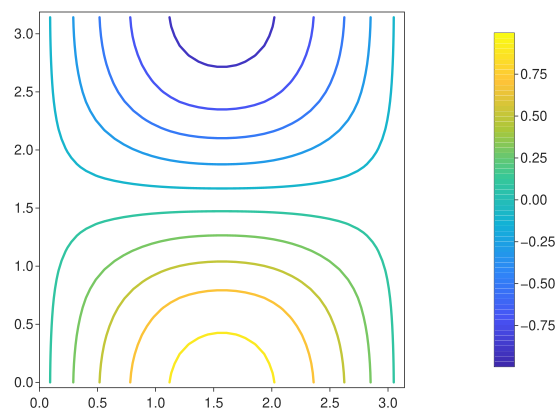

In [ ]:
[X, Y] = meshgrid(linspace(0, pi, 6));
Z = sin(X) .* cos(Y);
[Xf, Yf] = meshgrid(linspace(0, pi, 40));
Zf = interp2(X, Y, Z, Xf, Yf, 'cubic');
fprintf('largest error: linear %.4f, cubic %.4f\n', max(max(abs(interp2(X, Y, Z, Xf, Yf) - sin(Xf).*cos(Yf)))), ...
    max(max(abs(Zf - sin(Xf).*cos(Yf)))))
figure
contour(Xf, Yf, Zf, -0.9:0.2:0.9, 'LineWidth', 1.2), axis equal, colorbar

*Thanks to MatRust-Studio (MIT license), whose examples suggested these topics; the code here is Sagebrush's own.*